# Lab 00-02 · Where Abstractions Hold and Where They Leak

Companion to chapter [00-02](../../chapters/00-02-the-abstraction-stack.md). Handout: [README.md](README.md). Run all cells, then work through the **🔮 Predict** prompts.

In [1]:
import math, shutil, subprocess, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style; use_style()
except ImportError:
    pass
C0 = 299_792_458.0

## Part 1 — Lumped or not?

A structure is treated as lumped when its size is below about λ/10, with $\lambda = v/f$.

In [2]:
def lumped(size_m, freq_hz, v=C0):
    lam = v / freq_hz
    frac = size_m / lam
    verdict = "lumped" if frac < 0.1 else "transmission line (distributed)"
    print(f"size {size_m:g} m at {freq_hz:.3g} Hz: λ = {lam:.4g} m, size = {frac:.3g} λ  →  {verdict}")
    return frac

lumped(100e3, 60)               # power line
lumped(0.15, 2.5e9, v=1.5e8)    # board trace
lumped(2e-3, 3e9, v=C0 / math.sqrt(3.9))  # on-chip wire
assert abs(lumped(0.15, 2.5e9, v=1.5e8) - 2.5) < 1e-12

size 100000 m at 60 Hz: λ = 4.997e+06 m, size = 0.02 λ  →  lumped
size 0.15 m at 2.5e+09 Hz: λ = 0.06 m, size = 2.5 λ  →  transmission line (distributed)
size 0.002 m at 3e+09 Hz: λ = 0.0506 m, size = 0.0395 λ  →  lumped
size 0.15 m at 2.5e+09 Hz: λ = 0.06 m, size = 2.5 λ  →  transmission line (distributed)


## Part 2 — Digital regeneration versus analog accumulation

One million bits (0 V or 1 V) pass through N stages. Each stage adds Gaussian noise of standard deviation `sigma`. The **analog** chain keeps adding noise; the **digital** chain re-decides 0 or 1 at a 0.5 V threshold after every stage.

**🔮 Predict** (for `sigma = 0.2`): the per-stage error probability and the number of wrong bits after 10 stages. Hint: $Q(2.5) \approx 0.0062$.

per-stage error probability (theory)       : 0.00621
P(at least one error in 10 stages) (theory): 6.0390%
bits that were ever wrong (simulation)     : 60,058 of 1,000,000
analog noise σ after 10 stages: theory 0.6325 V, simulation 0.6328 V


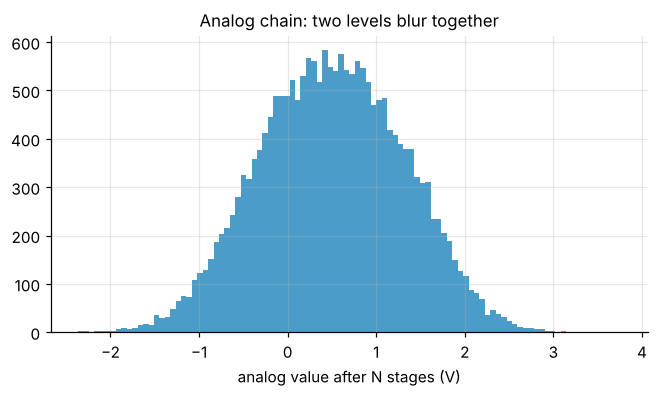

In [3]:
rng = np.random.default_rng(1)
n_bits, n_stages, sigma = 1_000_000, 10, 0.2     # <-- change sigma
bits = rng.integers(0, 2, n_bits).astype(float)
analog = bits.copy(); digital = bits.copy(); ever_wrong = np.zeros(n_bits, bool)
for _ in range(n_stages):
    analog += rng.normal(0, sigma, n_bits)
    digital = ((digital + rng.normal(0, sigma, n_bits)) > 0.5).astype(float)
    ever_wrong |= digital != bits
p = norm.sf(0.5 / sigma)
print(f"per-stage error probability (theory)       : {p:.4g}")
print(f"P(at least one error in {n_stages} stages) (theory): {1 - (1 - p) ** n_stages:.4%}")
print(f"bits that were ever wrong (simulation)     : {ever_wrong.sum():,} of {n_bits:,}")
print(f"analog noise σ after {n_stages} stages: theory {sigma * math.sqrt(n_stages):.4f} V, simulation {np.std(analog - bits):.4f} V")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(analog[:20000], bins=100, alpha=0.7); ax.set_xlabel("analog value after N stages (V)"); ax.set_title("Analog chain: two levels blur together")
plt.show()
assert abs(np.std(analog - bits) - sigma * math.sqrt(n_stages)) < 0.01

Note one subtlety: a digital stage can also *undo* an earlier error, if its own noise happens to flip a wrong bit back. "Ever wrong" counts bits that were wrong at any stage, which is what the theory formula $1 - (1-p)^N$ predicts.

## Part 3 — Reflections on a transmission line (Example 00-02.5)

The far-end voltage of an open-ended line is a sum of echoes (the lattice diagram): $v_{far}(t) = \sum_k 2\tau_s\,\Gamma_s^k\,x\big(t - (2k+1)T_D\big)$, where $\tau_s = Z_0/(R_s + Z_0)$ and $x(t)$ is the source waveform.

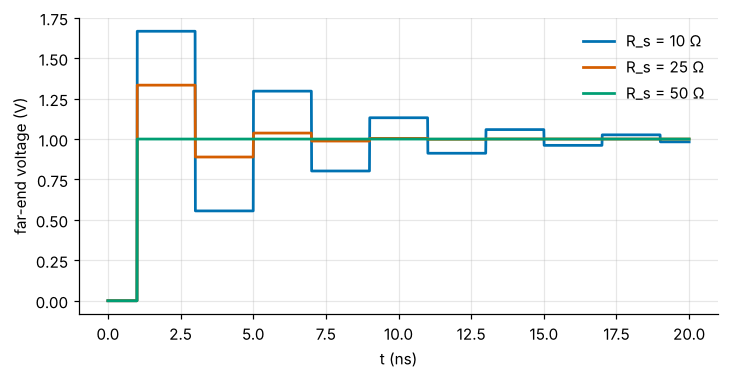

R_s = 10 Ω, far end at 1.5/3.5/5.5 ns: [1.6667 0.5556 1.2963]


In [4]:
def far_end(t, rs, z0=50.0, td=1e-9, t_rise=10e-12, n=300):
    gs, tau_s = (rs - z0) / (rs + z0), z0 / (rs + z0)
    k = np.arange(n)[:, None]
    x = np.clip((t[None, :] - (2 * k + 1) * td) / t_rise, 0, 1)
    return (2 * tau_s * gs ** k * x).sum(axis=0)

t = np.linspace(0, 20e-9, 4001)
fig, ax = plt.subplots(figsize=(7.5, 3.5))
for rs in [10, 25, 50]:                       # <-- try other source resistances
    ax.plot(t * 1e9, far_end(t, rs), label=f"R_s = {rs} Ω")
ax.set_xlabel("t (ns)"); ax.set_ylabel("far-end voltage (V)"); ax.legend(); plt.show()
v10 = far_end(np.array([1.5e-9, 3.5e-9, 5.5e-9]), 10)
print("R_s = 10 Ω, far end at 1.5/3.5/5.5 ns:", np.round(v10, 4))
assert np.allclose(v10, [5/3, 5/9, 35/27], atol=1e-6)

In [5]:
# Optional: run the ngspice netlist if ngspice is installed
if shutil.which("ngspice"):
    out = subprocess.run(["ngspice", "-b", "tline_reflections.cir"], capture_output=True, text=True).stdout
    print("\n".join(l for l in out.splitlines() if "=" in l and l.strip()[:3] in ("far", "max")))
else:
    print("ngspice not found; skipping (see SETUP.md).")

far1_a              =  1.666667e+00
far1_b              =  5.555556e-01
far1_c              =  1.296296e+00
max2                =  1.016001e+00 at=  5.100000e-08
far3_a              =  1.333333e+00
far3_b              =  8.888889e-01
far3_c              =  1.037037e+00
